<a href="https://colab.research.google.com/github/uf16/s-p-500-analysis/blob/main/S%26P500.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import requests
import io
headers = {'User-Agent': 'Mozilla/5.0'}
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'

# Get the content of the URL
response = requests.get(url, headers=headers)
tables = pd.read_html(response.text)


/tmp/ipykernel_801/892453868.py:9: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(response.text)


In [2]:
df_sp500 = tables[0]
df_sp500

,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989
...,...,...,...,...,...,...,...,...
498,XYL,Xylem Inc.,Industrials,Industrial Machinery & Supplies & Components,"White Plains, New York",2011-11-01,1524472,2011
499,YUM,Yum! Brands,Consumer Discretionary,Restaurants,"Louisville, Kentucky",1997-10-06,1041061,1997
500,ZBRA,Zebra Technologies,Information Technology,Electronic Equipment & Instruments,"Lincolnshire, Illinois",2019-12-23,877212,1969
501,ZBH,Zimmer Biomet,Health Care,Health Care Equipment,"Warsaw, Indiana",2001-08-07,1136869,1927


In [3]:
df_sp500 = df_sp500[['Symbol', 'Security', 'GICS Sector']]
df_sp500

,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
...,...,...,...
498,XYL,Xylem Inc.,Industrials
499,YUM,Yum! Brands,Consumer Discretionary
500,ZBRA,Zebra Technologies,Information Technology
501,ZBH,Zimmer Biomet,Health Care


In [4]:
df_sp500[df_sp500['GICS Sector'] =='Information Technology']

,Symbol,Security,GICS Sector
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
12,AKAM,Akamai Technologies,Information Technology
33,APH,Amphenol,Information Technology
...,...,...,...
451,TYL,Tyler Technologies,Information Technology
467,VRSN,Verisign,Information Technology
490,WDC,Western Digital,Information Technology
495,WDAY,"Workday, Inc.",Information Technology


In [5]:
import yfinance as yf

In [6]:
full_data = yf.download(df_sp500['Symbol'].to_list(), start= '2021-01-01', end= '2026-01-01')

/tmp/ipykernel_801/894279911.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  full_data = yf.download(df_sp500['Symbol'].to_list(), start= '2021-01-01', end= '2026-01-01')
[**********************48%                       ]  241 of 503 completedERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: BF.B"}}}
[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['FDXF', 'VYLR', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2026-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1767243600")')
ERROR:yfinance:['BF.B', 'BRK.B']: YFTzMissingError('possibly delisted; no timezone found')


In [7]:
data = full_data['Close']

In [8]:
import sqlite3
conn = sqlite3.connect('sp500.db')

In [9]:
df_melted = data.reset_index().melt(id_vars=['Date'], var_name='Ticker', value_name='Adj_Close')
df_melted.to_sql('stock_prices', conn, if_exists='replace')

631265

In [10]:
df_melted.head()

,Date,Ticker,Adj_Close
0,2021-01-04,A,114.009102
1,2021-01-05,A,114.941246
2,2021-01-06,A,118.093231
3,2021-01-07,A,121.235596
4,2021-01-08,A,122.100471


In [11]:
pd.read_sql('SELECT * FROM stock_prices limit 15', conn)

,index,Date,Ticker,Adj_Close
0,0,2021-01-04 00:00:00,A,114.009102
1,1,2021-01-05 00:00:00,A,114.941246
2,2,2021-01-06 00:00:00,A,118.093231
3,3,2021-01-07 00:00:00,A,121.235596
4,4,2021-01-08 00:00:00,A,122.100471
5,5,2021-01-11 00:00:00,A,123.147903
6,6,2021-01-12 00:00:00,A,122.013977
7,7,2021-01-13 00:00:00,A,122.023598
8,8,2021-01-14 00:00:00,A,121.110672
9,9,2021-01-15 00:00:00,A,121.283661


In [12]:
pd.read_sql('select min(Date), max(date) from stock_prices', conn)
pd.read_sql('select Ticker, Adj_Close from stock_prices where Date = "2021-01-04 00:00:00"', conn)

,Ticker,Adj_Close
0,A,114.009102
1,AAPL,125.537094
2,ABBV,84.219139
3,ABNB,139.149994
4,ABT,97.269722
...,...,...
498,XYZ,221.160004
499,YUM,95.016205
500,ZBH,141.603363
501,ZBRA,378.130005


In [13]:
df_recuperado = pd.read_sql('select * from stock_prices', conn)


In [95]:
df_ancho = df_recuperado.pivot(index = 'Date', columns= 'Ticker', values = 'Adj_Close')
df_ancho.index = pd.to_datetime(df_ancho.index)
df_ancho

Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009102,125.537094,84.219139,139.149994,97.269722,33.186359,232.029327,485.339996,132.622620,42.189487,...,26.124491,102.852112,54.757381,33.042770,93.015907,221.160004,95.016205,141.603363,378.130005,152.952042
2021-01-05,114.941246,127.089211,85.089996,148.300003,98.473206,33.319485,233.350250,485.690002,134.993134,43.010094,...,26.371325,106.017517,54.223660,34.635181,92.903908,229.750000,95.025177,144.053391,380.570007,154.017868
2021-01-06,118.093231,122.811203,84.354980,142.770004,98.268181,34.783871,235.901642,466.309998,135.601700,44.752838,...,26.506683,106.652519,55.424530,35.518982,96.822731,226.889999,95.545959,148.158356,394.820007,156.280502
2021-01-07,121.235596,127.001945,85.257797,151.270004,99.222061,34.460564,238.127258,477.739990,141.332779,44.355217,...,26.761482,105.594170,54.340405,35.797653,101.217422,239.479996,94.818665,147.280060,409.100006,156.140289
2021-01-08,122.100471,128.098129,85.705215,149.770004,99.498413,34.650742,238.995850,485.100006,142.359070,44.473660,...,26.578348,104.901443,54.840778,36.195751,100.191071,241.449997,96.210403,146.956451,405.470001,157.178070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-24,137.289749,272.859406,223.209625,136.779999,121.783112,96.400002,262.423798,352.980011,275.099640,56.189053,...,23.142776,123.752426,71.857536,116.142319,137.199127,66.050003,152.097153,89.274048,245.899994,122.722977
2025-12-26,137.359207,272.450836,223.297012,136.820007,121.812386,95.870003,263.502716,353.799988,274.386017,56.315475,...,23.123297,123.099121,72.177589,116.035172,137.268356,66.269997,151.032700,89.808319,246.270004,123.446655
2025-12-29,136.902649,272.809601,224.132034,136.619995,121.548935,96.389999,263.745697,353.160004,273.186768,56.616940,...,23.191479,121.030304,72.441483,117.418503,136.882675,65.919998,150.076675,89.570877,245.740005,123.202179


In [96]:
primera_fila = df_ancho.iloc[0]
normalizacion = (df_ancho *100) / primera_fila

In [26]:
normalizacion

Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04 00:00:00,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,...,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
2021-01-05 00:00:00,100.817605,101.236381,101.034037,106.575645,101.237264,100.401145,100.569291,100.072116,101.787413,101.945049,...,100.944837,103.077628,99.025297,104.819242,99.879591,103.884064,100.009443,101.730204,100.645281,100.696837
2021-01-06 00:00:00,103.582284,97.828617,100.161295,102.601517,101.026485,104.813759,101.668890,96.079038,102.246284,106.075804,...,101.462967,103.695021,101.218372,107.493959,104.092659,102.590882,100.557541,104.629122,104.413827,102.176147
2021-01-07 00:00:00,106.338524,101.166867,101.233280,108.710033,102.007140,103.839542,102.628086,98.434086,106.567627,105.133339,...,102.438293,102.666020,99.238501,108.337324,108.817325,108.283592,99.792098,104.008871,108.190305,102.084475
2021-01-08 00:00:00,107.097126,102.040062,101.764535,107.632060,102.291249,104.412603,103.002432,99.950552,107.341470,105.414079,...,101.737287,101.992503,100.152303,109.542120,107.713910,109.174350,101.256837,103.780340,107.230317,102.762976
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-24 00:00:00,120.419990,217.353610,265.034323,98.296805,125.201459,290.480798,113.099409,72.728399,207.430407,133.182591,...,88.586517,120.320744,131.228949,351.490863,147.500714,29.865257,160.074961,63.045147,65.030543,80.236246
2025-12-26 00:00:00,120.480913,217.028153,265.138085,98.325558,125.231555,288.883760,113.564401,72.897348,206.892322,133.482246,...,88.511952,119.685555,131.813442,351.166595,147.575141,29.964729,158.954675,63.422448,65.128395,80.709387
2025-12-29 00:00:00,120.080456,217.313936,266.129572,98.181819,124.960710,290.450658,113.669121,72.765485,205.988065,134.196794,...,88.772941,117.674107,132.295374,355.353082,147.160501,29.806474,157.948505,63.254767,64.988232,80.549549


In [31]:
pip install matplotlib

In [91]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

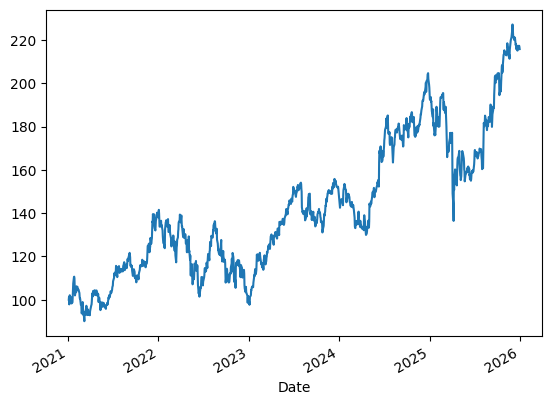

In [97]:
aapl_grafico = normalizacion['AAPL'].plot()
aapl_grafico.xaxis.set_major_locator(mdates.YearLocator())
plt.show()

In [110]:
lst_year = normalizacion.iloc[-1]
lst_year.sort_values(ascending= False).head(10)

,2025-12-31
Ticker,
FIX,1852.359449
NVDA,1426.198254
SMCI,942.673117
VST,935.314538
AVGO,904.763239
VRT,878.574494
TRGP,779.174493
HWM,773.445973
PLTR,760.590473


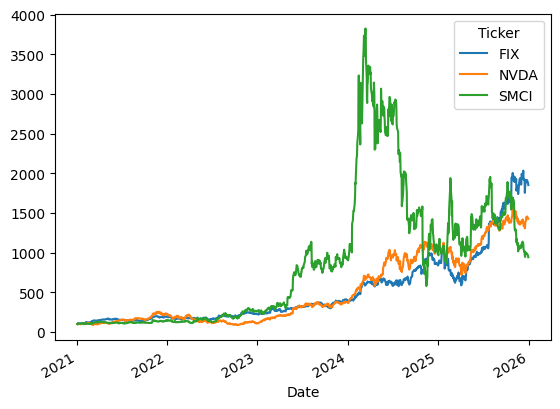

In [115]:
top_graficos = normalizacion[['FIX', 'NVDA', 'SMCI']].plot()
top_graficos.xaxis.set_major_locator(mdates.YearLocator())
plt.show()